In [1]:
from pathlib import Path

root = Path.cwd()
if not (root / "data" / "raw" / "PhenoBench-v110" / "PhenoBench").exists():
    root = root.parent

data_root = root / "data" / "raw" / "PhenoBench-v110" / "PhenoBench"

for split in ["train", "val", "test"]:
    image_dir = data_root / split / "images"
    n = len(list(image_dir.glob("*.png")))
    print(f"{split}: {n} images")

train: 1407 images
val: 772 images
test: 693 images


In [4]:
import numpy as np
from PIL import Image

img_p = sorted((data_root/"train"/"images").glob("*.png"))[0]
msk_p = data_root/"train"/"semantics"/img_p.name
img = np.array(Image.open(img_p).convert("RGB"))
msk = np.array(Image.open(msk_p))
print(img.shape, img.dtype)   # kỳ vọng (1024, 1024, 3) uint8
print(msk.shape, msk.dtype)   # kỳ vọng (1024, 1024), uint16

(1024, 1024, 3) uint8
(1024, 1024) uint16


In [6]:
from collections import Counter
total = Counter()
for p in sorted((data_root/"train"/"semantics").glob("*.png")):
    m = np.array(Image.open(p))
    ids, cnt = np.unique(m, return_counts=True)
    total.update(dict(zip(ids.tolist(), cnt.tolist())))
print(sorted(total.items()))

[(0, 1293238516), (1, 153463715), (2, 7078797), (3, 21310522), (4, 254882)]


In [12]:
import numpy as np
from PIL import Image
from pathlib import Path

root = Path.cwd()
if not (root / "data" / "raw" / "PhenoBench-v110" / "PhenoBench").exists():
    root = root.parent

data_root = root / "data" / "raw" / "PhenoBench-v110" / "PhenoBench"
sem_dir = data_root / "train" / "semantics"

rows = []
for p in sorted(sem_dir.glob("*.png")):
    m = np.array(Image.open(p))
    rows.append((p.name, int((m == 3).sum()), int((m == 4).sum())))

top3 = sorted(rows, key=lambda r: -r[1])[:5]   # nhiều ID 3 nhất
top4 = sorted(rows, key=lambda r: -r[2])[:5]   # nhiều ID 4 nhất
print("ID 3:", top3)
print("ID 4:", top4)

ID 3: [('06-05_00202_P0038055.png', 251591, 0), ('06-05_00137_P0038055.png', 247426, 0), ('06-05_00158_P0038055.png', 188828, 0), ('06-05_00180_P0038055.png', 187920, 0), ('06-05_00181_P0038055.png', 184761, 0)]
ID 4: [('06-05_00224_P0038053.png', 86717, 6808), ('06-05_00109_P0037820.png', 23154, 6659), ('06-05_00130_P0037820.png', 22812, 6659), ('06-05_00182_P0038053.png', 40548, 5561), ('05-26_00242_P0034018.png', 26104, 5510)]


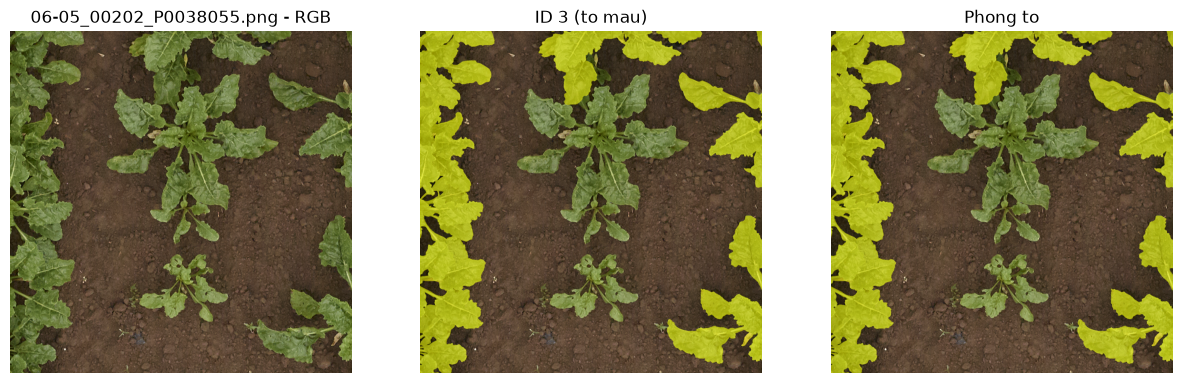

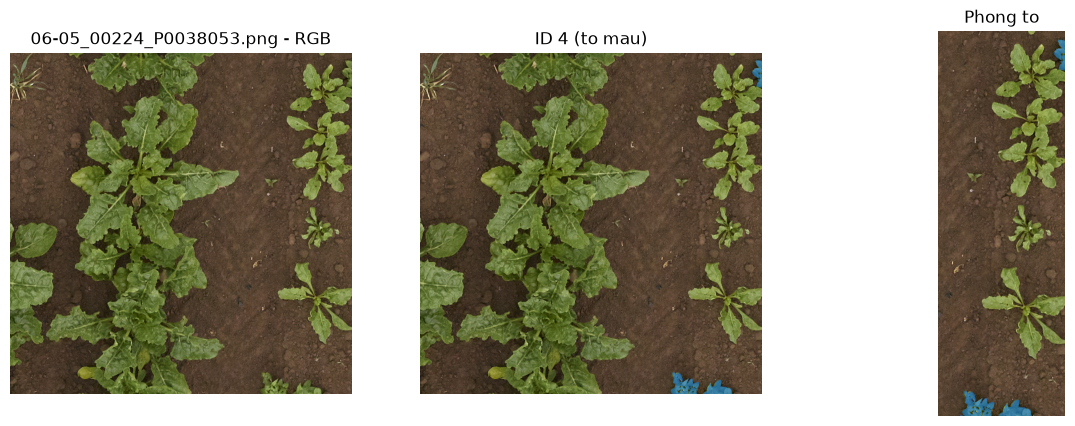

In [15]:
import matplotlib.pyplot as plt

def show_id(name, target_id, color):
    img = np.array(Image.open(data_root / "train" / "images" / name).convert("RGB"))
    m = np.array(Image.open(data_root / "train" / "semantics" / name))
    over = img.copy()
    over[m == target_id] = color
    over = (0.5 * img + 0.5 * over).astype(np.uint8)

    ys, xs = np.where(m == target_id)
    y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()
    pad = 60
    y0, x0 = max(0, y0 - pad), max(0, x0 - pad)
    y1, x1 = min(1024, y1 + pad), min(1024, x1 + pad)

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(img)
    ax[0].set_title(f"{name} - RGB")
    ax[1].imshow(over)
    ax[1].set_title(f"ID {target_id} (to mau)")
    ax[2].imshow(over[y0:y1, x0:x1])
    ax[2].set_title("Phong to")
    for a in ax:
        a.axis("off")
    plt.show()

show_id(top3[0][0], 3, (255, 255, 0))
show_id(top4[0][0], 4, (0, 120, 255))

thống nhất id3->crop, id4->weed

In [16]:
def border_fraction(m, target_id, margin=20):
    mask = (m == target_id)
    if mask.sum() == 0:
        return None
    border = np.zeros_like(mask)
    border[:margin, :] = border[-margin:, :] = True
    border[:, :margin] = border[:, -margin:] = True
    return (mask & border).sum() / mask.sum()

for tid in (3, 4):
    vals = []
    for p in sorted(sem_dir.glob("*.png"))[:200]:
        v = border_fraction(np.array(Image.open(p)), tid)
        if v is not None:
            vals.append(v)
    print(tid, "ty le pixel nam sat mep (TB):", np.mean(vals))

3 ty le pixel nam sat mep (TB): 0.6346001352905242
4 ty le pixel nam sat mep (TB): 0.9082891388632505


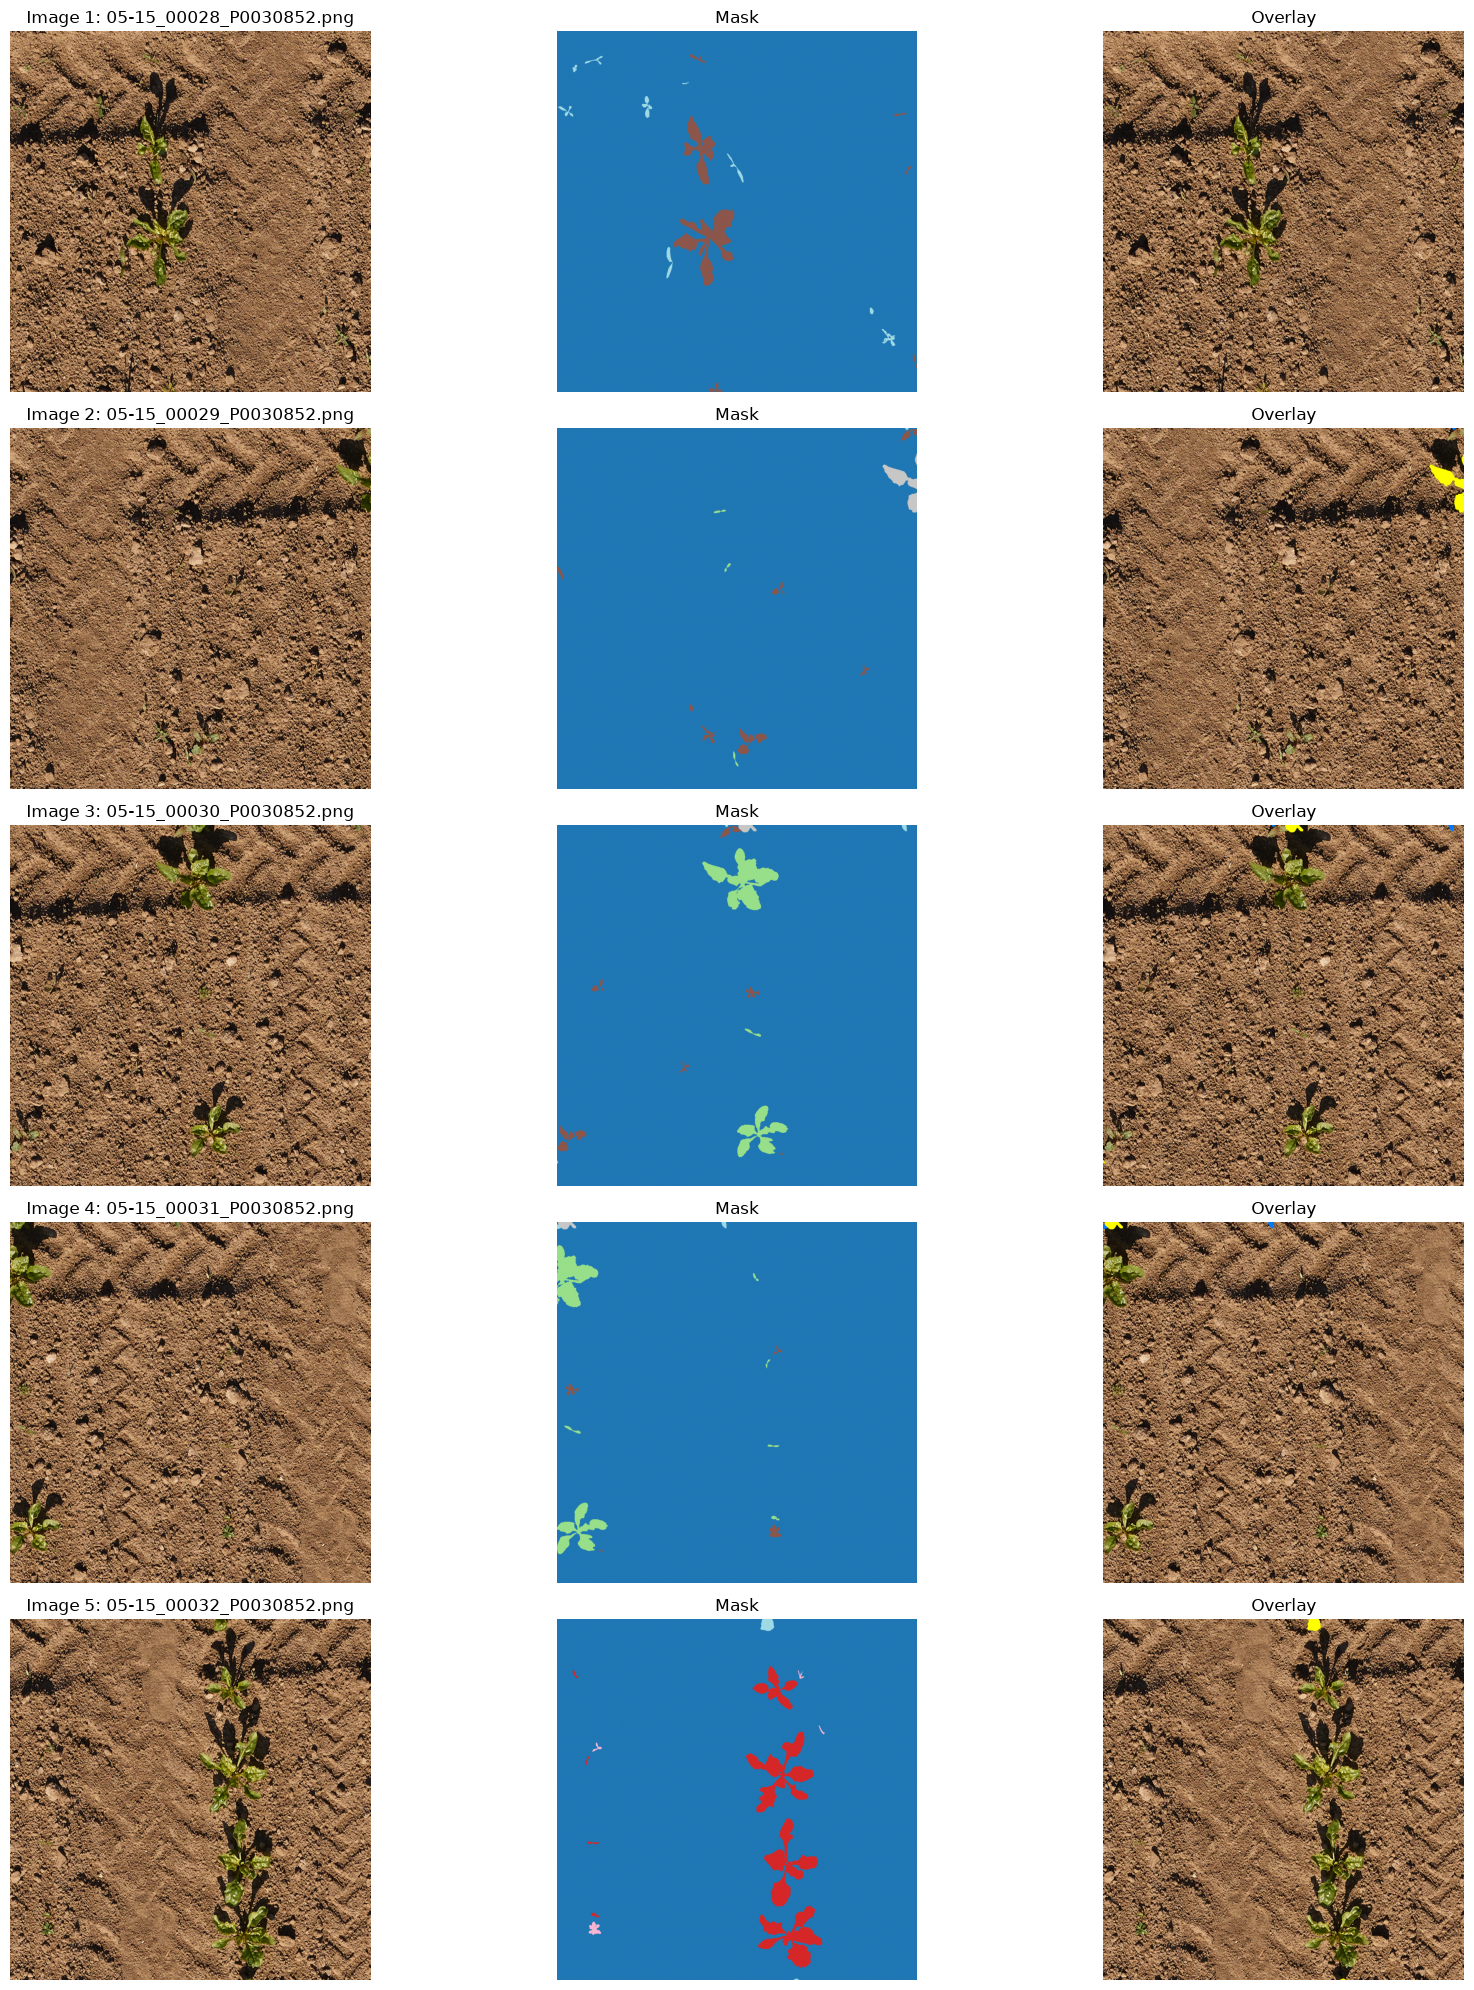

In [17]:

# Hiển thị 5 ảnh và mask kề nhau để xác định lớp
import matplotlib.pyplot as plt

sample_files = sorted((data_root / "train" / "images").glob("*.png"))[:5]

fig, axes = plt.subplots(len(sample_files), 3, figsize=(18, 4 * len(sample_files)))
for i, img_path in enumerate(sample_files):
    msk_path = data_root / "train" / "semantics" / img_path.name
    img = np.array(Image.open(img_path).convert("RGB"))
    msk = np.array(Image.open(msk_path))

    ax_img, ax_msk, ax_overlay = axes[i]
    ax_img.imshow(img)
    ax_img.set_title(f"Image {i+1}: {img_path.name}")
    ax_img.axis("off")

    ax_msk.imshow(msk, cmap="tab20")
    ax_msk.set_title("Mask")
    ax_msk.axis("off")

    overlay = img.copy()
    overlay[msk == 3] = [255, 255, 0]
    overlay[msk == 4] = [0, 120, 255]
    ax_overlay.imshow(overlay)
    ax_overlay.set_title("Overlay")
    ax_overlay.axis("off")

plt.tight_layout()
plt.show()
